In [1]:
import xarray as xr, numpy as np, pandas as pd
import matplotlib.pyplot as plt, cartopy.crs as ccrs
import matplotlib.cm as cm, matplotlib.colors as mcolors
from matplotlib.patches import Patch
import cartopy.feature as cfeature

from functions import build_country_weights, verify_population_coverage, EU_MEMBERS,\
                        country_weights_dict, baseline_start, baseline_end, lat_to_str_dict, \
                        cider_inj_lats_popweighted, basepath, cpath, cider_combined, pop, \
                        countries_zip_path, select_eu_mode, reorient_netcdf, areaweighted_mean

<xarray.Dataset> Size: 9MB
Dimensions:  (time: 60, lat: 96, lon: 192)
Coordinates:
  * time     (time) object 480B 2029-11-15 00:00:00 ... 2034-10-16 00:00:00
  * lat      (lat) float64 768B -88.57 -86.72 -84.86 -83.0 ... 84.86 86.72 88.57
  * lon      (lon) float64 2kB -178.1 -176.2 -174.4 -172.5 ... 176.2 178.1 180.0
Data variables:
    T        (time, lat, lon) float64 9MB -0.002623 -0.002623 ... -1.335 -1.336
Attributes:
    CDI:          Climate Data Interface version 2.0.4 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    description:  Dataset converted from NumPy array with dimensions (lon, la...
    history:      Mon Oct 19 14:16:48 2026: cdo -remapbil,/home/msaenger/REST...
    CDO:          Climate Data Operators version 2.0.4 (https://mpimet.mpg.de...

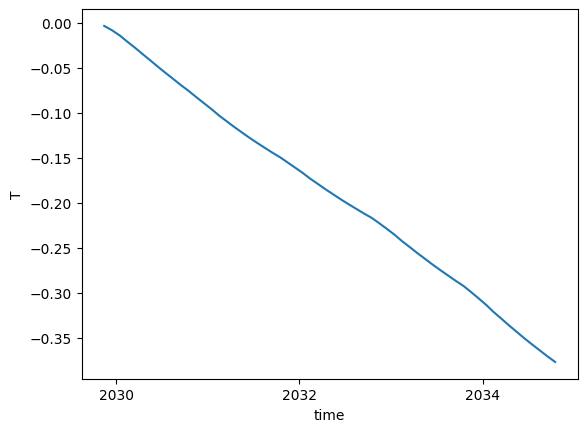

In [2]:
## CMIP7 stabilization scenario in which optimal injection rates for 1.5C stabilization are deployed
## at 30S and 30N simultaneously

cider_cmip7_stabilize = reorient_netcdf(xr.open_dataset(
    '/home/msaenger/CIDER/CMIP7_stabilization/TREFHT/002_1.0_Tgyr.nc_regridded.nc'))

areaweighted_mean(cider_cmip7_stabilize.T).plot()

cider_cmip7_stabilize

In [3]:
n_members = 500
newpath = basepath + f'{n_members}_members/' 

ssp_plus_invert = xr.open_dataset(newpath + 
                    f'SSP370_plus_InVERT_{n_members}member_ensemble_TREFHT_2015_to_2065.nc')

baseline = ssp_plus_invert.sel(time=slice(baseline_start, baseline_end))

baseline

<xarray.Dataset> Size: 9GB
Dimensions:   (time: 120, lat: 96, ensemble: 500, lon: 192)
Coordinates:
  * time      (time) object 960B 2015-01-16 00:00:00 ... 2024-12-16 00:00:00
  * lat       (lat) float64 768B -88.57 -86.72 -84.86 ... 84.86 86.72 88.57
    month     (time) int64 960B ...
  * ensemble  (ensemble) int64 4kB 0 1 2 3 4 5 6 ... 493 494 495 496 497 498 499
  * lon       (lon) float64 2kB -178.1 -176.2 -174.4 ... 176.2 178.1 180.0
Data variables:
    TREFHT    (time, lat, lon, ensemble) float64 9GB ...
    gmean     (time, ensemble) float64 480kB ...

In [4]:
## Load 'Default' test results for min injection rate to convince population of success

### Values of sensitivity-tested parameters
buffer_months = 12
tau = 12
eval_months = 36

### Where results are saved for this set of parameters
rpath = newpath + \
        f'results_buffer={buffer_months}m_tau={tau}m_eval={eval_months}m/'
print(rpath)

k_setting = 'country_k'
eu_mode = 'aggregated'

/home/msaenger/Perceptions_2025/cleaned_code/500_members/results_buffer=12m_tau=12m_eval=36m/


In [5]:
## Folded country polygons (labels match country_da/W_norm_eu exactly) 
countries = country_weights_dict['countries_gdf']

## Sanity check that every grid cell's population is accounted for in the country rows
verify_population_coverage(country_weights_dict)

PASSED -- Population coverage: 100.000000% (8.016736e+09 of 8.016736e+09 people-equivalent) accounted for across kept country rows.


{'population_total': 8016736089.992069,
 'population_accounted': 8016736089.992069,
 'coverage_frac': 1.0,
 'passed': True}

In [6]:
## Load min injection rate datasets with NaNs replaced with max possible rate

inj_rates_single_lat = xr.open_dataset(rpath + \
                            f'single_lat_min_rates_{k_setting}_EU_agg_nans_replaced.nc')
inj_rates_uniform = xr.open_dataset(rpath + \
                            f'global_uniform_min_rates_{k_setting}_EU_agg_nans_replaced.nc')

### Plot maps of dT and dP for  percentile injection rates for each deploying country

In [7]:
def compute_var_diff(deploying_country, pctile, injection_type,
                     inj_rates_single_lat, inj_rates_uniform,
                     year, cider_da):
    '''
    Compute the gridded difference between year N of a CIDER SAI  injection run and the counterfactual
    (no SAI from CIDER)
    Inputs:
        deploying_country (str)
        pctile (int, 0-100): percentile of the country's minimum injection
            rate distribution to evaluate CIDER at
        injection_type (str): 'single_lat' or 'uniform'
        year (int): 1 or 2 (first or second 12 months of the run)
        cider_da: raw CIDER DataArray (dims include injection_lat, injection_rate, time) 
            -- the CIDER *delta*, not yet combined with any background
    Returns:
        mean_diff (lat, lon): SAI forced response, mean over the chosen year
        pctile_rate (float): the injection rate (Tg/yr) this was evaluated at
    '''
    if injection_type not in ('single_lat', 'uniform'):
        raise ValueError(f"injection_type must be 'single_lat' or 'uniform', got {injection_type!r}")
    year_slices = {1: slice(0, 12), 2: slice(12, 24)}
    if year not in year_slices:
        raise ValueError(f'year must be 1 or 2, got {year!r}')

    min_rates_ds = inj_rates_single_lat if injection_type == 'single_lat' else inj_rates_uniform
    min_rates = min_rates_ds.sel(country=deploying_country).min_injection_rate.values
    min_rates = min_rates[~np.isnan(min_rates)]
    if min_rates.size == 0:
        raise ValueError(f'No valid min injection rates for {deploying_country} ({injection_type})')

    ## Choose nearest higher percentile value from available data
    pctile_rate = np.percentile(min_rates, pctile, method='higher')

    if injection_type == 'single_lat':
        inj_lat = lat_to_str_dict[cider_inj_lats_popweighted.sel(
                        country=deploying_country).nearest_cider_lat.values.tolist()]
        var_cider = cider_da.sel(injection_lat=inj_lat, injection_rate=pctile_rate)
    else:
        var_cider = cider_da.sel(injection_lat='uniform', injection_rate=pctile_rate)

    diff = var_cider.isel(time=year_slices[year])

    mean_diff = diff.mean('time')

    return mean_diff, pctile_rate, year

In [8]:
def compute_stabilize_diff(stabilize_da, year):
    '''
    Mean over year 1 or 2 of the CMIP7 stabilization run (optimized inj in Tg/yr at 30S + 30N).
    Same time slicing as compute_var_diff().
    Returns: mean_diff (lat, lon)
    '''
    year_slices = {1: slice(0, 12), 2: slice(12, 24)}
    if year not in year_slices:
        raise ValueError(f'year must be 1 or 2, got {year!r}')
    diff = stabilize_da.isel(time=year_slices[year])

    return diff.mean('time')

In [9]:
def compute_T_diff(deploying_country, pctile, injection_type, 
                    inj_rates_single_lat, inj_rates_uniform, 
                    year, cider_da=cider_combined):
    '''
    Gridded TREFHT mean delta (K) in year 1 or 2 of a CIDER SAI injection run.
    Thin T-specific wrapper around compute_var_diff() -- see that docstring for details.

    Returns:
        T_diff (lat, lon, in K), pctile_rate (float, Tg/yr), year
    '''
    return compute_var_diff(deploying_country, pctile, injection_type, 
                              inj_rates_single_lat, inj_rates_uniform, 
                              year, cider_da)

In [10]:
## Load baseline precip data
ppath = '/home/msaenger/Perceptions_2025/cleaned_code/LENS2_SSP370/precip/'
baseline_precip = xr.open_dataset(ppath + 'PRECT_combined_2015-2024.nc')

## Load combined CIDER precip dataset
cider_output_path = basepath + 'CIDER_output/PRECIP/'
cider_precip_combined = xr.open_dataset(cider_output_path + \
                'CIDER_PRECT_output_combined_1.0_Tg_increments_first_5_years.nc').P
cider_precip_combined

<xarray.DataArray 'P' (injection_lat: 8, injection_rate: 250, time: 60,
                       lat: 96, lon: 192)> Size: 18GB
[2211840000 values with dtype=float64]
Coordinates:
  * lat             (lat) float64 768B -88.57 -86.72 -84.86 ... 86.72 88.57
  * lon             (lon) float64 2kB -178.1 -176.2 -174.4 ... 176.2 178.1 180.0
  * injection_rate  (injection_rate) float64 2kB 1.0 2.0 3.0 ... 249.0 250.0
  * injection_lat   (injection_lat) <U7 224B '60S' '30S' ... '60N' 'uniform'
  * time            (time) int64 480B 0 1 2 3 4 5 6 7 ... 53 54 55 56 57 58 59
Attributes:
    CDI_grid_type:     gaussian
    CDI_grid_num_LPE:  48

In [11]:
## CMIP7 stabilization scenario for precip: same optimized injection rates as above for TREFHT
cider_precip_cmip7_stabilize = reorient_netcdf(
                                    xr.open_dataset('/home/msaenger/CIDER/CMIP7_stabilization/' + \
                                                    'PRECT/002_1.0_PRECT_Tgyr.nc_PRECT_regridded.nc'))

cider_precip_cmip7_stabilize

<xarray.Dataset> Size: 9MB
Dimensions:  (time: 60, lat: 96, lon: 192)
Coordinates:
  * time     (time) object 480B 2029-11-15 00:00:00 ... 2034-10-16 00:00:00
  * lat      (lat) float64 768B -88.57 -86.72 -84.86 -83.0 ... 84.86 86.72 88.57
  * lon      (lon) float64 2kB -178.1 -176.2 -174.4 -172.5 ... 176.2 178.1 180.0
Data variables:
    P        (time, lat, lon) float64 9MB ...
Attributes:
    CDI:          Climate Data Interface version 2.0.4 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    description:  Dataset converted from NumPy array with dimensions (lon, la...
    history:      Mon Oct 19 14:18:37 2026: cdo -remapbil,/home/msaenger/REST...
    CDO:          Climate Data Operators version 2.0.4 (https://mpimet.mpg.de...

In [12]:
## Convert longitude to -180 to 180 from 0-360
baseline_precip = reorient_netcdf(baseline_precip)

## Convert baseline_precip from m/s (CESM/LENS2 native units) to mm/day to match CIDER units
## 1 m/s * 1000 mm/m * 86400 s/day = 86,400,000 mm/day per (m/s)
M_PER_S_TO_MM_PER_DAY = 1000 * 86400
baseline_precip['PRECT'] = baseline_precip['PRECT'] * M_PER_S_TO_MM_PER_DAY
baseline_precip['PRECT'].attrs['units'] = 'mm/day'

baseline_precip

<xarray.Dataset> Size: 885MB
Dimensions:   (ensemble: 50, time: 120, lat: 96, lon: 192)
Coordinates:
  * time      (time) object 960B 2015-01-16 00:00:00 ... 2024-12-16 00:00:00
  * lat       (lat) float64 768B -88.57 -86.72 -84.86 ... 84.86 86.72 88.57
  * ensemble  (ensemble) int64 400B 0 1 2 3 4 5 6 7 ... 42 43 44 45 46 47 48 49
  * lon       (lon) float64 2kB -178.1 -176.2 -174.4 ... 176.2 178.1 180.0
Data variables:
    PRECT     (ensemble, time, lat, lon) float64 885MB 0.02946 ... 0.7837
Attributes:
    CDI:          Climate Data Interface version 2.0.4 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    history:      Mon Jul 27 15:54:01 2026: cdo -remapbil,/home/msaenger/REST...
    CDO:          Climate Data Operators version 2.0.4 (https://mpimet.mpg.de...

In [13]:
def compute_P_diff(deploying_country, pctile, injection_type,
                     inj_rates_single_lat, inj_rates_uniform,
                     year, cider_da=cider_precip_combined):
    '''
    Gridded precipitation delta (mm/day) averaged across year 1 or 2 of a CIDER SAI 
    injection run. Thin P-specific wrapper around compute_var_diff() 
    Returns:
        P_diff (lat, lon, in mm/day), pctile_rate (float, Tg/yr), year
    '''
    return compute_var_diff(deploying_country, pctile, injection_type,
                               inj_rates_single_lat, inj_rates_uniform,
                               year, cider_da)

### Combined T & P difference maps: temperature (top row) and precipitation (bottom row), aligned by injection strategy (columns)

In [29]:
## Per-band CMIP7-stabilization injection (Tg/yr at EACH of 30S and 30N) by SAI year, from the
## optimal-injection table at the bottom of this notebook (per_band_injection, year_index 0 and 1)
STABILIZE_PER_BAND_TG = {1: 0.7551463040912798, 2: 0.8678207363066286}


def plot_gridded_TP_diff_comparison(deploying_country, inj_rates_single_lat, inj_rates_uniform, 
                                    pctile, year, 
                                    injection_types=('single_lat', 'uniform'),
                                    vmax_T=None, vmax_P=None,
                                    precip_scale='symlog',
                                    linthresh_P=None,
                                    stabilize_T=cider_cmip7_stabilize.T,
                                    stabilize_P=cider_precip_cmip7_stabilize.P):
    '''
    Plot temp and precip CIDER difference maps for one deploying country

    Inputs mirror the individual T/P comparison functions:
        deploying_country (str)
        inj_rates_single_lat, inj_rates_uniform: injection-rate datasets
        pctile (int, 0-100): percentile of the country's minimum injection
            rate distribution to evaluate CIDER at
        year (int): 1 or 2, year of SAI deployment to average over
        injection_types (tuple of str): 'uniform' and/or 'single_lat',
            one column per entry, in the given order
        vmax_T, vmax_P (float, optional): shared symmetric color limits for
            the temp and precip rows respectively. Defaults to the 95th percentile of 
            |diff| across all columns
        precip_scale (str): 'symlog' (default; symmetric-log norm) or 'linear' for the precip row
        linthresh_P (float, optional): symlog only. Half-width of the linear zone of the 
            symmetric-log precip color scale (mm/day). Defaults to the median |dP| of the 
            stabilize column
        stabilize_T, stabilize_P: CMIP7 stabilization T and P DataArrays (optimized injection 
            at 30S + 30N), plotted as an extra rightmost column
    '''
    import os

    if precip_scale not in ('symlog', 'linear'):
        raise ValueError(f"precip_scale must be 'symlog' or 'linear', got {precip_scale!r}")
    if year not in STABILIZE_PER_BAND_TG:
        raise ValueError(f'year must be 1 or 2, got {year!r}')

    ## Compute T and P difference maps for each injection strategy
    T_diffs, T_rates = {}, {}
    P_diffs, P_rates = {}, {}
    
    for injection_type in injection_types:
        
        T_diff, T_pctile_rate, _ = compute_T_diff(deploying_country, pctile, injection_type,
                                                  inj_rates_single_lat, inj_rates_uniform, year)
        T_diffs[injection_type] = T_diff
        T_rates[injection_type] = T_pctile_rate

        P_diff, P_pctile_rate, _ = compute_P_diff(deploying_country, pctile, injection_type,
                                                  inj_rates_single_lat, inj_rates_uniform, year)
        P_diffs[injection_type] = P_diff
        P_rates[injection_type] = P_pctile_rate

    ## CMIP7 stabilization scenario as an additional column
    T_diffs['stabilize'] = compute_stabilize_diff(stabilize_T, year)
    P_diffs['stabilize'] = compute_stabilize_diff(stabilize_P, year)
    T_rates['stabilize'] = P_rates['stabilize'] = STABILIZE_PER_BAND_TG[year]
    col_keys = list(injection_types) + ['stabilize']

    if vmax_T is None:
        vmax_T = max(np.nanpercentile(np.abs(T_diffs[it]), 95) for it in col_keys)
    if vmax_P is None:
        vmax_P = max(np.nanpercentile(np.abs(P_diffs[it]), 95) for it in col_keys)
    
    vmin_T = -vmax_T
    vmin_P = -vmax_P

    ## Precip color scaling
    if precip_scale == 'symlog':
        ## Symmetric-log norm: linear within +/-linthresh_P, log outside
        if linthresh_P is None:
            linthresh_P = np.nanpercentile(np.abs(P_diffs['stabilize']), 50)
        ## Guard against a degenerate (zero/NaN) threshold, and keep it inside the plotted range
        if not np.isfinite(linthresh_P) or linthresh_P <= 0:
            linthresh_P = vmax_P / 100
        linthresh_P = min(linthresh_P, vmax_P)
        norm_P = mcolors.SymLogNorm(linthresh=linthresh_P, linscale=0.5,
                                    vmin=vmin_P, vmax=vmax_P, base=10)
        P_plot_kwargs = dict(norm=norm_P)
        file_suffix = ''
    else:
        P_plot_kwargs = dict(vmin=vmin_P, vmax=vmax_P)
        file_suffix = '_linearP'

    n_cols = len(col_keys)
    fig, axes = plt.subplots(2, n_cols, figsize=(7.5 * n_cols, 8), squeeze=False,
                             subplot_kw={'projection': ccrs.Robinson()})

    def _injection_title(injection_type):
        pctile_rate = T_rates[injection_type]
        if injection_type == 'stabilize':
            return ('CMIP7 stabilization\n'
                    #f'{pctile_rate:.2f} Tg/yr at each of 30S and 30N'
                    '1.7 Tg/yr total')
        if injection_type == 'single_lat':
            inj_lat = lat_to_str_dict[cider_inj_lats_popweighted.sel(
                            country=deploying_country).nearest_cider_lat.values.tolist()]
            return (f'Single latitude injection\n'
                    f'{pctile_rate:.0f} Tg/yr at {inj_lat}')
        else:
            return (f'Globally uniform injection\n'
                    f'{pctile_rate:.0f} Tg/yr total')

    ## Panel letters: top row (a, b, c, ...) then bottom row continues the alphabet
    panel_labels = [(chr(ord('a') + c), chr(ord('a') + n_cols + c)) for c in range(n_cols)]
    panel_labels = [(f'({t})', f'({b})') for t, b in panel_labels]
    
    T_mappable = P_mappable = None
        
    for col, injection_type in enumerate(col_keys):
        label = panel_labels[col]

        ## Top row: temperature
        ax_T = axes[0, col]
        T_mappable = T_diffs[injection_type].plot(
            ax=ax_T, cmap='RdBu_r',
            vmin=vmin_T, vmax=vmax_T,
            transform=ccrs.PlateCarree(),
            zorder=0, add_colorbar=False)
        
        ax_T.add_feature(cfeature.BORDERS, linewidth=0.3, zorder=2)
        ax_T.add_feature(cfeature.OCEAN, color='gainsboro', zorder=1)
        ax_T.add_feature(cfeature.COASTLINE, linewidth=0.5, zorder=2)
        ax_T.set_title(_injection_title(injection_type), fontsize=18)
        
        ax_T.text(0.02, 1.06, label[0], transform=ax_T.transAxes, fontsize=14,
                fontweight='bold', va='top', ha='left', zorder=10)
            
        ## Bottom row: precipitation (same column/injection strategy)
        ax_P = axes[1, col]
        P_mappable = P_diffs[injection_type].plot(
            ax=ax_P, cmap='BrBG',
            transform=ccrs.PlateCarree(),
            zorder=0, add_colorbar=False, **P_plot_kwargs)
        
        ax_P.add_feature(cfeature.BORDERS, linewidth=0.3, zorder=2)
        ax_P.add_feature(cfeature.OCEAN, color='gainsboro', zorder=1)
        ax_P.add_feature(cfeature.COASTLINE, linewidth=0.5, zorder=2)
        ax_P.set_title('')
        
        ax_P.text(0.02, 1.06, label[1], transform=ax_P.transAxes,
                fontsize=14, fontweight='bold', va='top', ha='left',
                zorder=10)

    ## Two separate colorbars, one per row, on the right-hand side
    fig.subplots_adjust(right=0.9, hspace=0.05, wspace=0.05)

    cbar_ax_T = fig.add_axes([0.91, 0.51, 0.015, 0.35])   # [left, bottom, width, height]
    cbar_T = fig.colorbar(T_mappable, cax=cbar_ax_T)
    cbar_T.ax.tick_params(labelsize=12)
    cbar_T.set_label('$\\Delta$T [K]', fontsize=14)

    cbar_ax_P = fig.add_axes([0.91, 0.11, 0.015, 0.35])
    cbar_P = fig.colorbar(P_mappable, cax=cbar_ax_P)
    cbar_P.ax.tick_params(labelsize=12)
    cbar_P.set_label('$\\Delta$P [mm/day]', fontsize=14)
    
    if precip_scale == 'symlog':
        ## Ticks at 0, +/-linthresh, +/- each decade above it, and +/-vmax
        decades = 10.0 ** np.arange(np.ceil(np.log10(linthresh_P)), np.floor(np.log10(vmax_P)) + 1)
        pos = np.unique(np.concatenate([[linthresh_P], decades[decades <= vmax_P], [vmax_P]]))
        ticks = np.concatenate([-pos[::-1], [0], pos])
        cbar_P.set_ticks(ticks)
        cbar_P.set_ticklabels([f'{t:.2g}' for t in ticks])
        cbar_P.ax.minorticks_off()

#     plt.suptitle(f'Year {year} of SAI deployed by {deploying_country} \n' + \
#                  'Mean SAI-forced change relative to background',
#                  y=1.04, fontsize=22)

    os.makedirs(rpath + 'Plots/', exist_ok=True)
    stem = (rpath + f'Plots/{deploying_country}_dT_dP_map_{pctile}th_pctile_' +
            f'{k_setting}{file_suffix}')
    plt.savefig(stem + '.pdf', bbox_inches='tight')
    plt.savefig(stem + '.png', bbox_inches='tight')


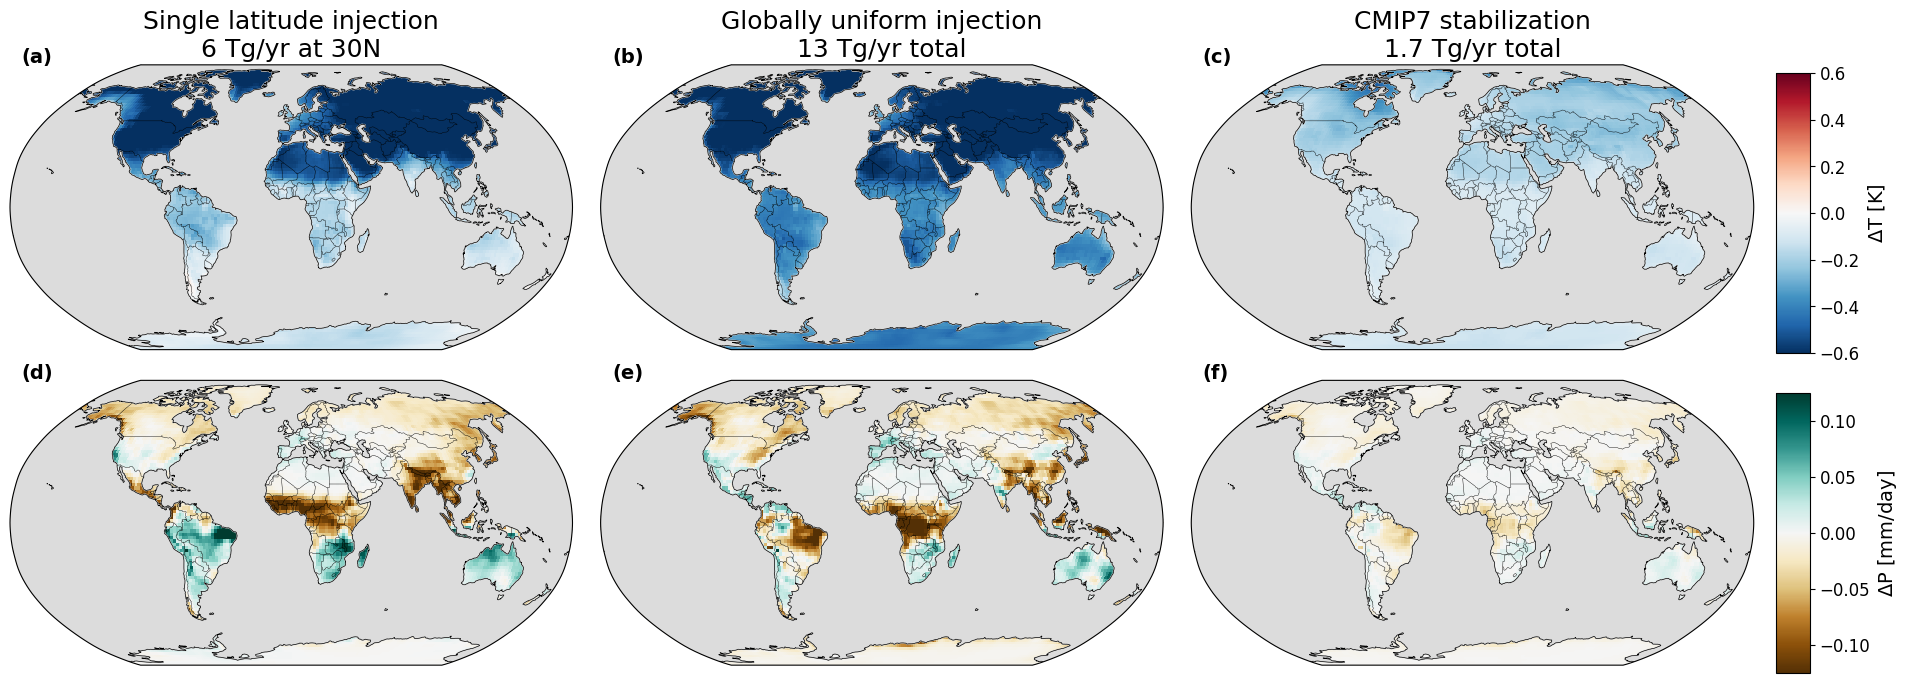

In [30]:
vmax_T = 0.6
vmax_P = 0.125

deploying_country = 'United States of America'

plot_gridded_TP_diff_comparison(deploying_country, inj_rates_single_lat, inj_rates_uniform,
                                pctile=90, year=2, vmax_T=vmax_T, vmax_P=vmax_P,
                                precip_scale='linear')   


### 'optimal injection rates'
calculated in CIDER_30S_30N_1_5_optimal_injection_with_piControl_baseline.ipynb

year_index,per_band_injection,total_injection
0,0.7551463040912798,1.5102926081825596
1,0.8678207363066286,1.7356414726132572
2,1.0536207348747086,2.1072414697494173
3,1.343751361321637,2.687502722643274
4,1.6520428885415797,3.3040857770831593

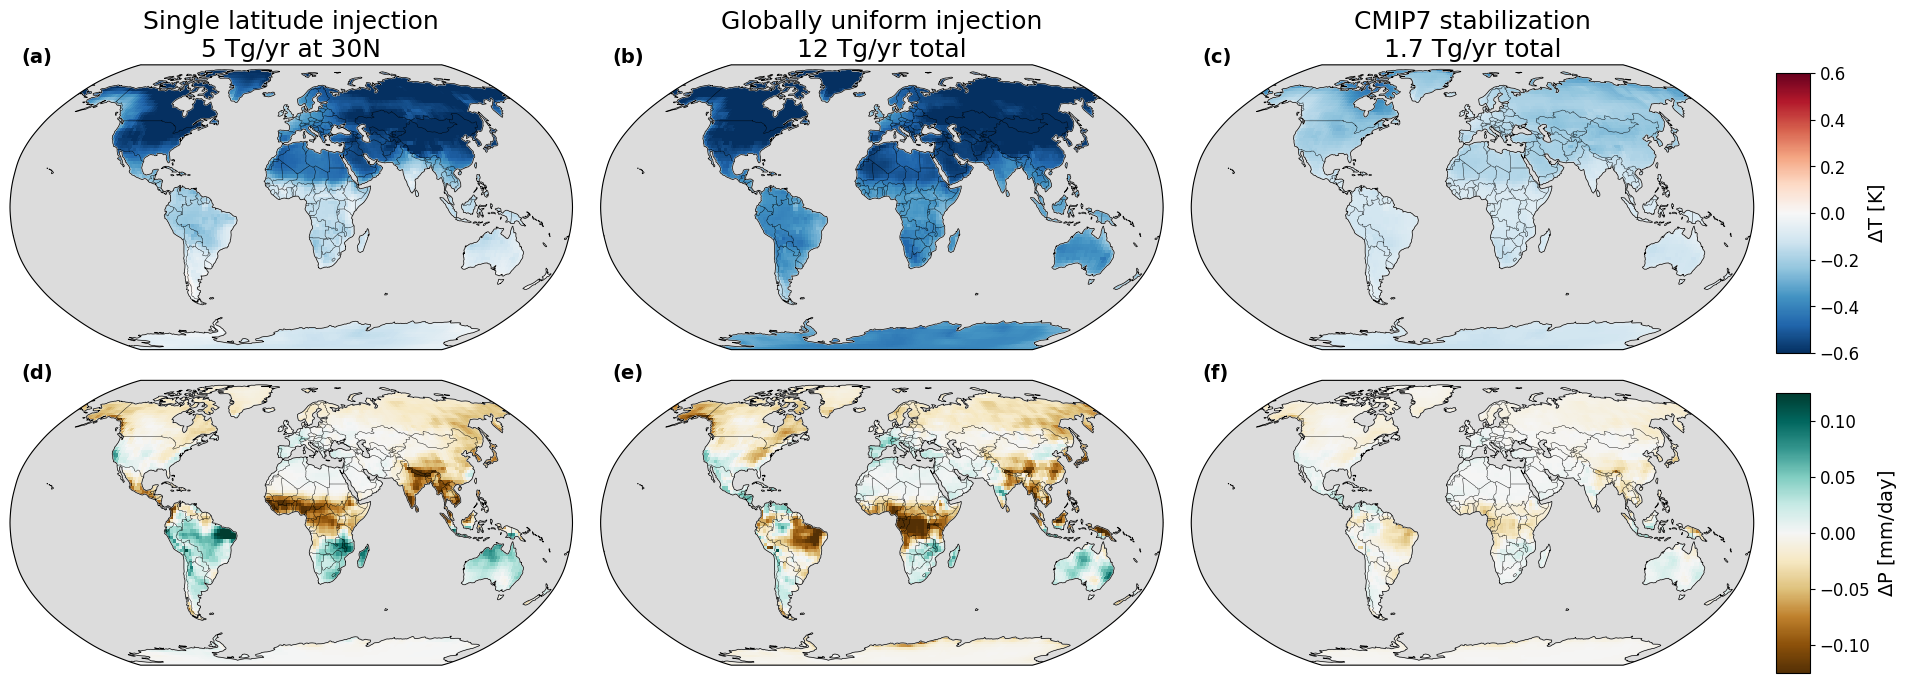

In [31]:
vmax_T = 0.6
vmax_P = 0.125

deploying_country = 'China'

plot_gridded_TP_diff_comparison(deploying_country, inj_rates_single_lat, inj_rates_uniform,
                                pctile=90, year=2, vmax_T=vmax_T, vmax_P=vmax_P,
                                precip_scale='linear')   

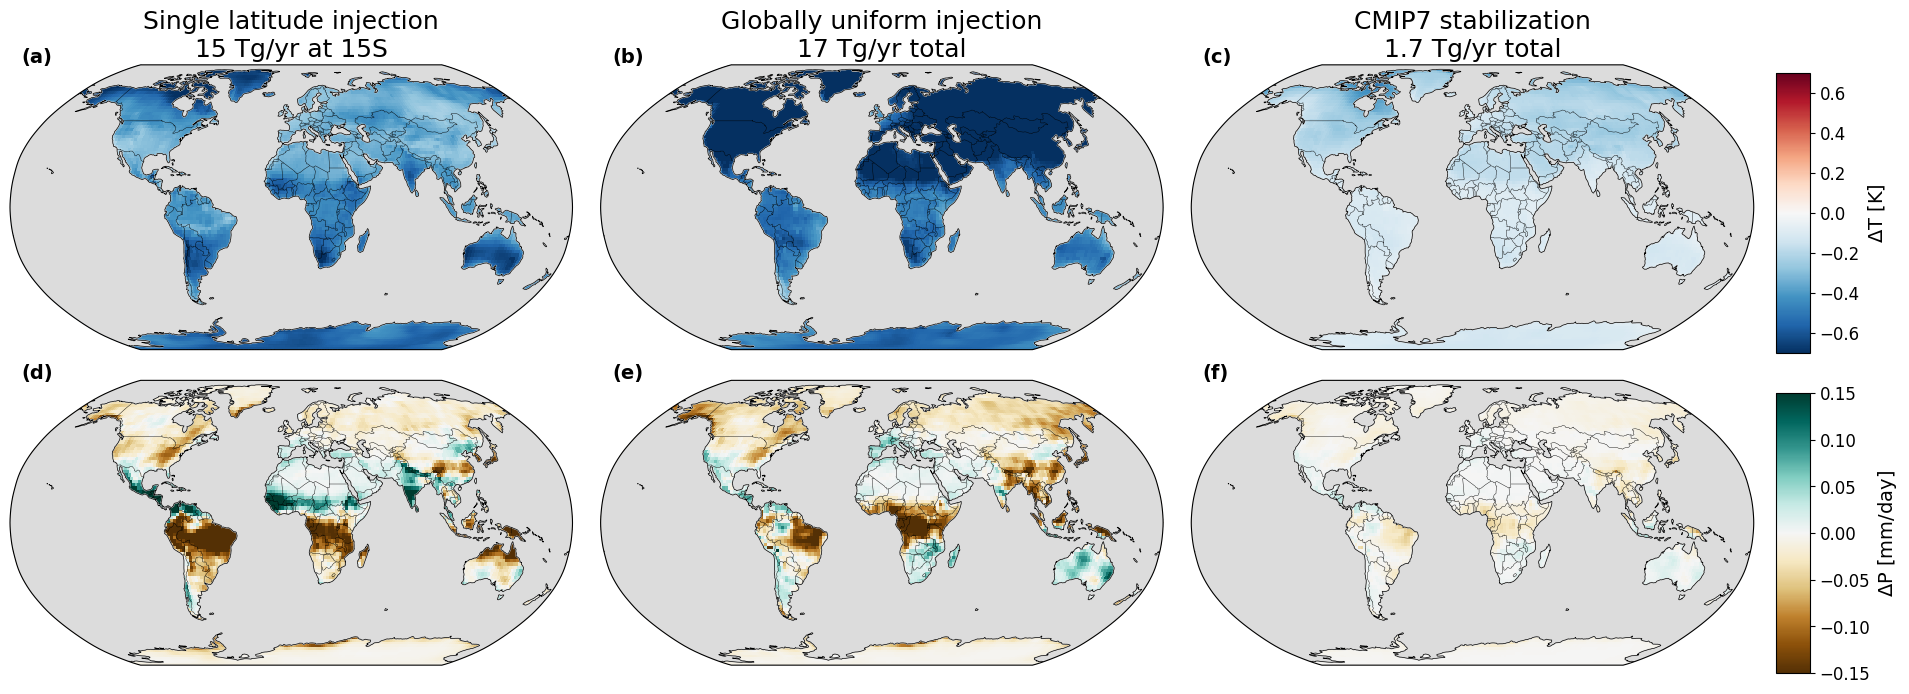

In [36]:
vmax_T = 0.7
vmax_P = 0.15

deploying_country = 'Brazil'

plot_gridded_TP_diff_comparison(deploying_country, inj_rates_single_lat, inj_rates_uniform,
                                pctile=90, year=2, vmax_T=vmax_T, vmax_P=vmax_P,
                                precip_scale='linear')   

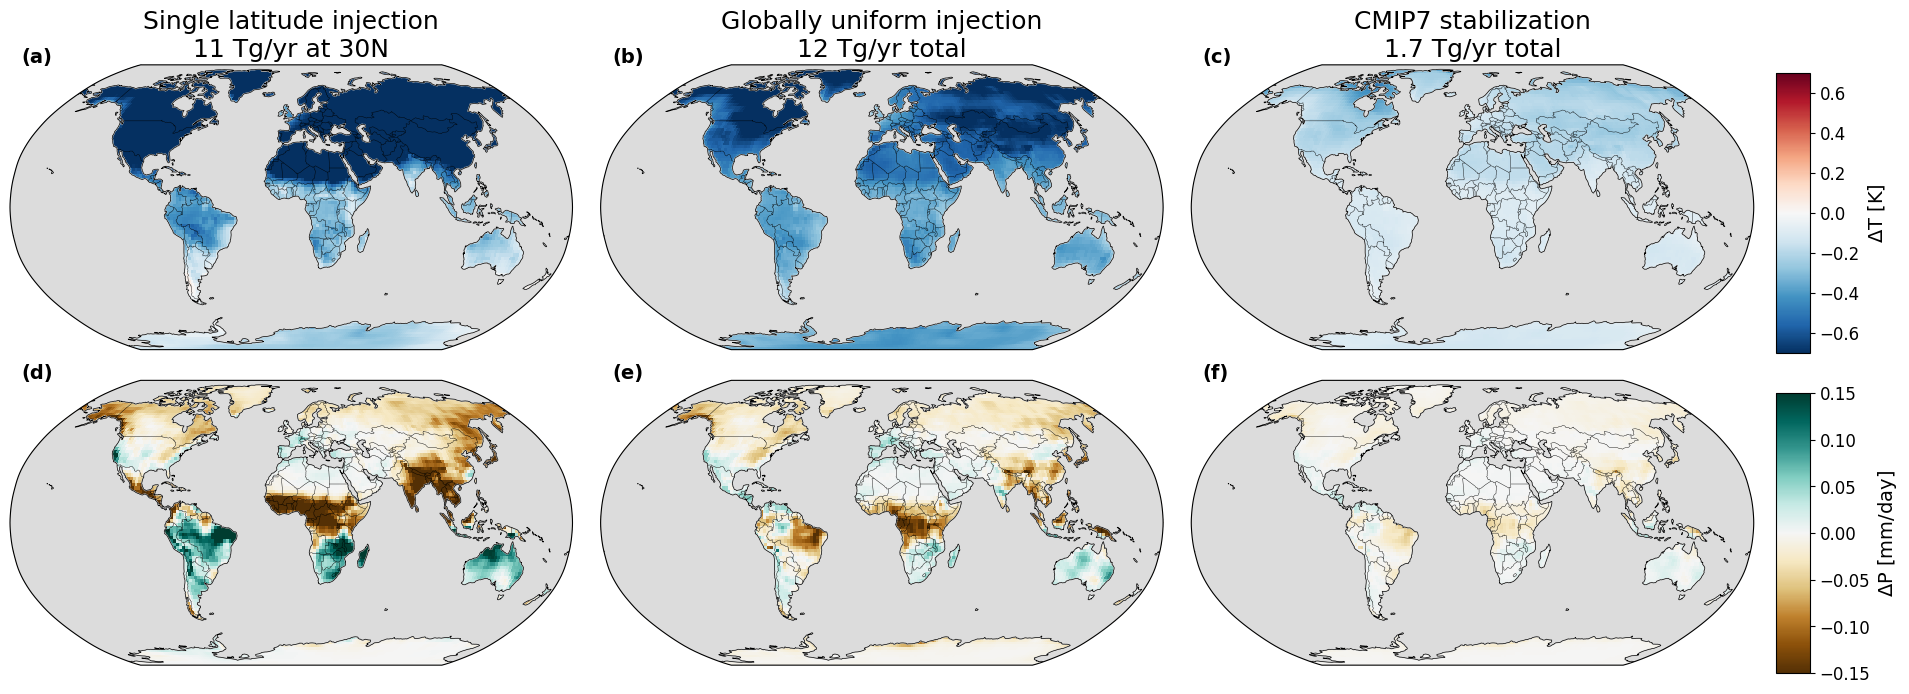

In [37]:
vmax_T = 0.7
vmax_P = 0.15

deploying_country = 'India'

plot_gridded_TP_diff_comparison(deploying_country, inj_rates_single_lat, inj_rates_uniform,
                                pctile=90, year=2, vmax_T=vmax_T, vmax_P=vmax_P,
                                precip_scale='linear')   

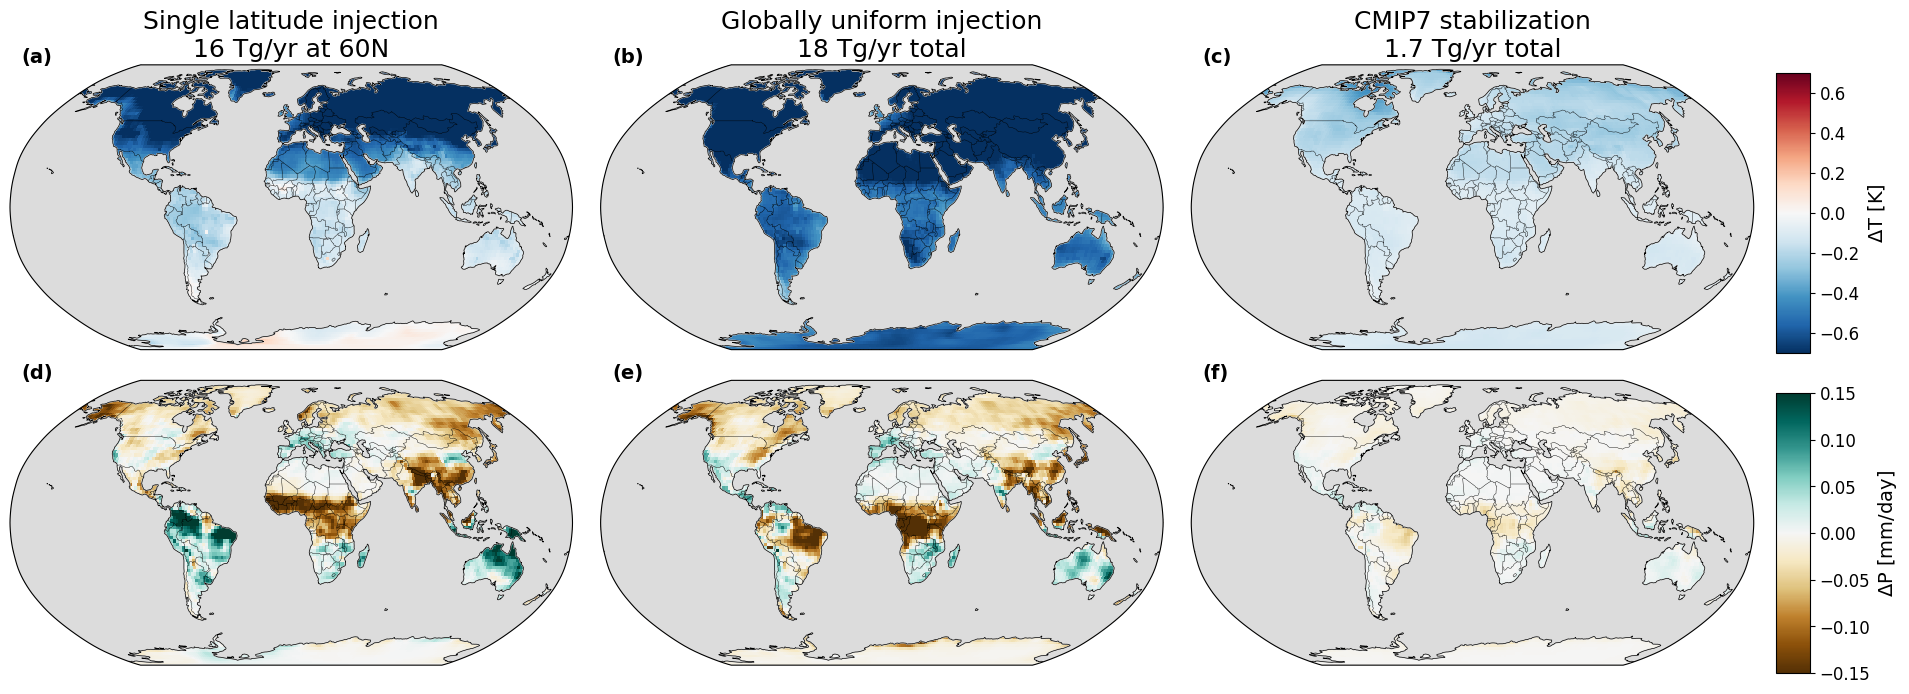

In [38]:
vmax_T = 0.7
vmax_P = 0.15

deploying_country = 'European Union'

plot_gridded_TP_diff_comparison(deploying_country, inj_rates_single_lat, inj_rates_uniform,
                                pctile=90, year=2, vmax_T=vmax_T, vmax_P=vmax_P,
                                precip_scale='linear')   

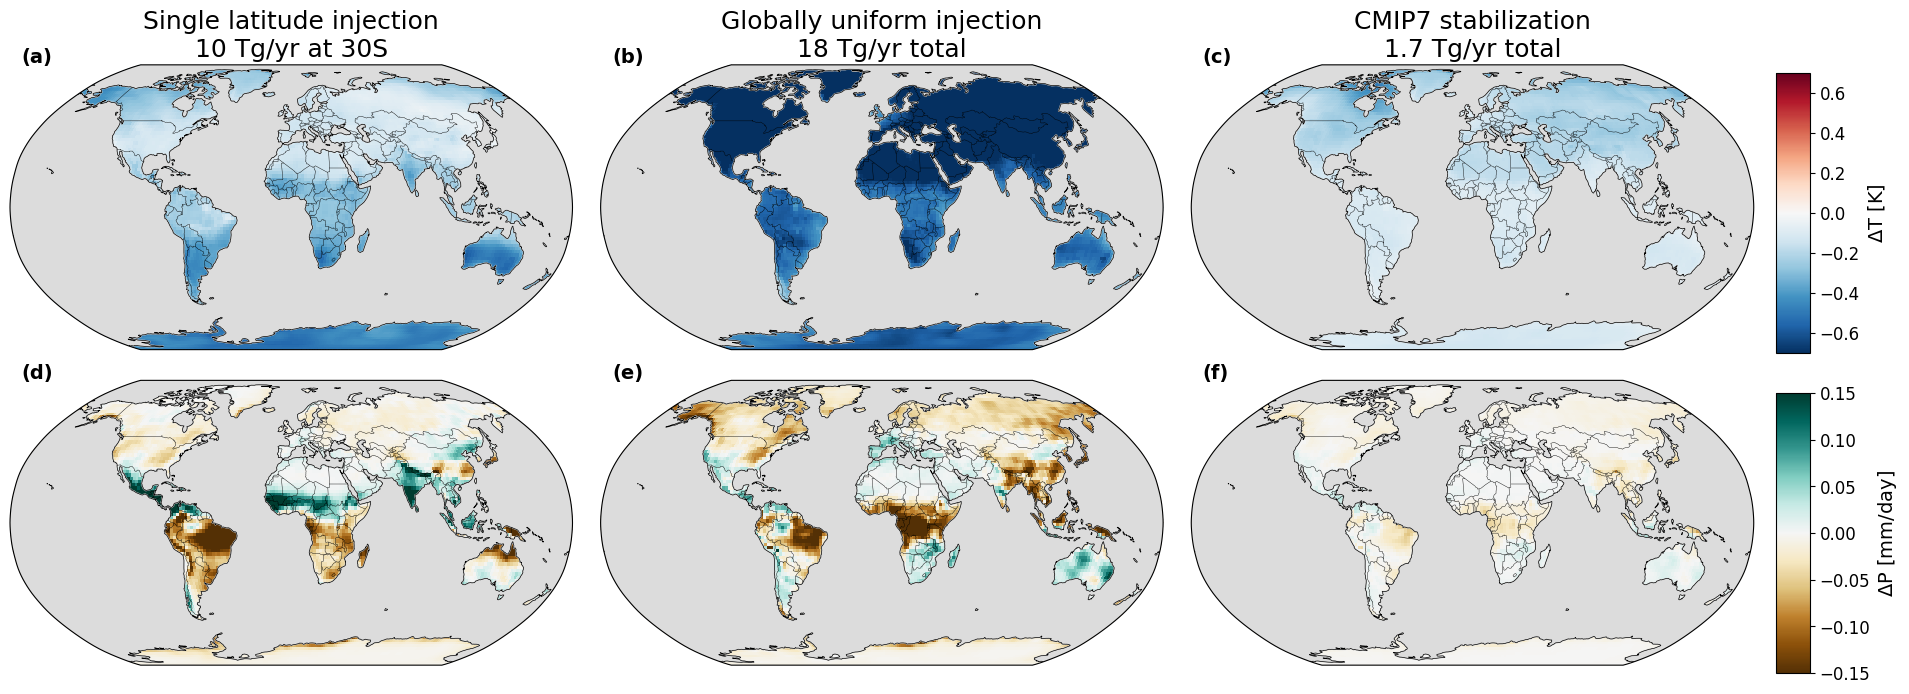

In [39]:
vmax_T = 0.7
vmax_P = 0.15

deploying_country = 'Australia'

plot_gridded_TP_diff_comparison(deploying_country, inj_rates_single_lat, inj_rates_uniform,
                                pctile=90, year=2, vmax_T=vmax_T, vmax_P=vmax_P,
                                precip_scale='linear')   